# Frozen W_in + W_out: does W_rec alone learn cog20?

Single-network `cmc.moo_zoom` runs (not batched) with `--freeze w_in,w_out --w-out-init fanin`: the input and
readout stay at their random init (readout at randn/√n_E, so it carries signal), only W_rec and the biases
learn. Reference: the **trainable** control of the 4-point zoom (`dale_all_4pt_12seed_50k`, 12 seeds, 50k steps,
batched).

`RUNS` lists the run directories; one row/curve per network.

In [1]:
import contextlib, io, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import default_config, rule_name
from cmc.train_cog import load_checkpoint, make_dale_model

RUNS = ["control_100k_freeze_fanin_2seed", "single_control_70k_freeze_win_wout", "single_knee_70k_freeze_win_wout"]
REF = ("dale_all_4pt_12seed_50k", "control")          # trainable control, for comparison

nets = []   # one dict per network
for run in RUNS:
    d = MOO_ZOOM_RUNS_DIR / run
    summ = json.loads((d / "summary.json").read_text())
    for r in pd.read_csv(d / "runs.csv").itertuples():
        with contextlib.redirect_stdout(io.StringIO()):
            model, cfg, ck = load_checkpoint(d / r.checkpoint)
            m0 = make_dale_model(default_config(n_eachring=16, seed=0), **ck["model_kwargs"])
        W, W0 = model.effective_w_rec().detach().numpy(), m0.effective_w_rec().detach().numpy()
        nets.append(dict(name=f"{r.point} s{r.seed} frozen ({summ['steps'] // 1000}k)", run=run, row=r._asdict(),
                         label=f"{r.point}{' (constrained)' if r.point != 'control' else ''} weight frozen "
                               f"{summ['steps'] // 1000}k, seed {r.seed}",
                         steps=summ["steps"],
                         hist=ck["history"], freeze=ck["history"].get("freeze"),
                         w_out_std=float(model.w_out.detach().std()),
                         W_corr_init=np.corrcoef(W.ravel(), W0.ravel())[0, 1],
                         W_rel_change=np.linalg.norm(W - W0) / np.linalg.norm(W0)))
TASKS = list(nets[0]["hist"]["per_task"])
TNAME = [rule_name[t] for t in TASKS]          # Yang 2019 display names
ref = pd.read_csv(MOO_ZOOM_RUNS_DIR / REF[0] / "runs.csv")
ref = ref[ref.point == REF[1]]

display(pd.DataFrame([{**{k: n["row"][k] for k in ("point", "seed", "rate_budget", "conn_budget", "min_task_acc",
                                                   "mean_acc", "metabolic_cost", "conn_frac")},
                       "freeze": n["freeze"], "W_out std": n["w_out_std"],
                       "W_rec corr(init)": n["W_corr_init"], "W_rec |dW|/|W0|": n["W_rel_change"],
                       "hours": n["row"]["train_time_s"] / 3600} for n in nets], index=[n["name"] for n in nets]).round(4))
print(f"reference (trainable {REF[1]}, {len(ref)} seeds): min_task_acc {ref.min_task_acc.mean():.3f}, "
      f"mean_acc {ref.mean_acc.mean():.3f}")

,point,seed,rate_budget,conn_budget,min_task_acc,mean_acc,metabolic_cost,conn_frac,freeze,W_out std,W_rec corr(init),W_rec |dW|/|W0|,hours
control s0 frozen (100k),control,0,NaN,NaN,0.4156,0.8127,1.9586,0.6645,"[w_in, w_out]",0.0700,0.6080,1.8035,5.8466
control s1 frozen (100k),control,1,NaN,NaN,0.4734,0.8460,1.1692,0.7506,"[w_in, w_out]",0.0712,0.7303,1.1802,6.0820
control s0 frozen (70k),control,0,NaN,NaN,0.3531,0.7632,2.2251,0.6787,"[w_in, w_out]",0.0700,0.6732,1.4551,3.9680
knee s0 frozen (70k),knee,0,0.0046,0.0025,0.1734,0.2365,0.0067,0.0019,"[w_in, w_out]",0.0700,0.0722,2.4172,4.2981


reference (trainable control, 12 seeds): min_task_acc 0.864, mean_acc 0.979


## Final accuracy per task
One row per network (red = chance, green = solved); bottom row: the trainable control (mean of its seeds).

In [2]:
nets[0]['name']

'control s0 frozen (100k)'

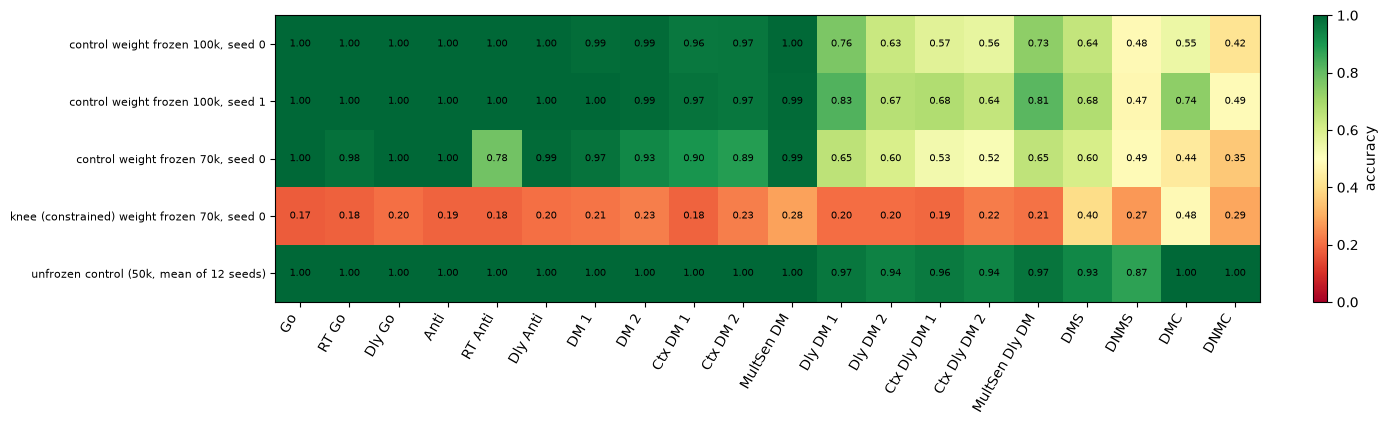

In [3]:
rows = [[n["row"][f"acc_{t}"] for t in TASKS] for n in nets] + [[ref[f"acc_{t}"].mean() for t in TASKS]]
artificial_labels = [n["label"] for n in nets] + [f"unfrozen control (50k, mean of {len(ref)} seeds)"]
labels = [n["name"] for n in nets] + [f"{REF[1]} trainable (50k, {len(ref)} seeds)"]
A = np.array(rows)
fig, ax = plt.subplots(figsize=(14, 0.55 * len(A) + 1.6))
im = ax.imshow(A, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(TASKS))); ax.set_xticklabels(TNAME, rotation=60, ha="right")
ax.set_yticks(range(len(A))); ax.set_yticklabels(artificial_labels, fontsize=8)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="accuracy", fraction=0.02)
plt.tight_layout(); plt.show()

## Accuracy per task over training

From the training log (`history["per_task"]`, evaluated every `log_every` steps on 64 trials, noise-free;
noisier than the final eval). One panel per task, one line per network.

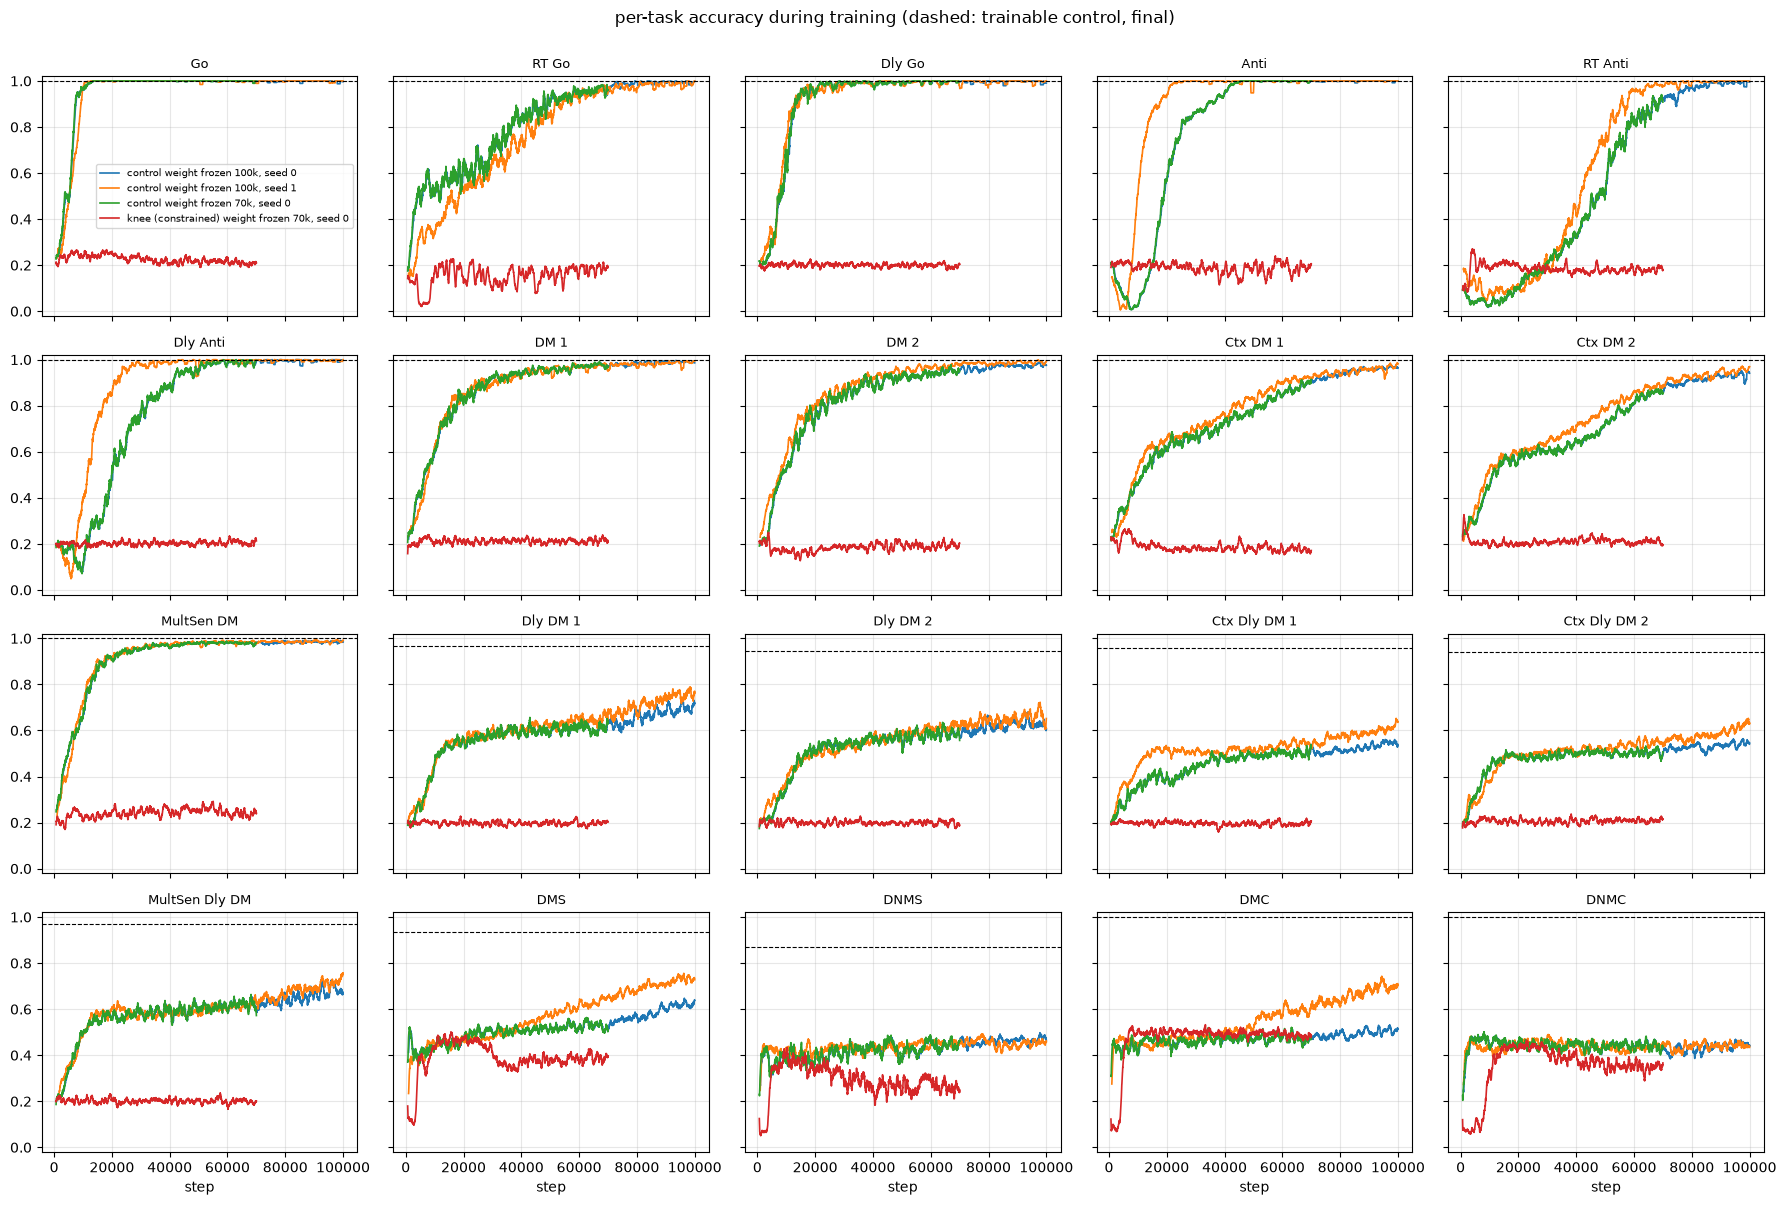

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(18, 12), sharex=True, sharey=True)
for ax, t in zip(axes.flat, TASKS):
    for i, n in enumerate(nets):
        steps = np.asarray(n["hist"]["eval_step"])
        acc = np.asarray(n["hist"]["per_task"][t]["acc"], dtype=float)
        k = max(1, len(acc) // 100)                                  # light smoothing
        sm = np.convolve(acc, np.ones(k) / k, mode="valid")
        ax.plot(steps[k - 1:], sm, color=f"C{i}", lw=1.2, label=n["label"])
    ax.axhline(ref[f"acc_{t}"].mean(), color="k", ls="--", lw=0.8)
    ax.set_title(rule_name[t], fontsize=9); ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("step")
axes[0, 0].legend(fontsize=7); fig.suptitle("per-task accuracy during training (dashed: trainable control, final)", y=1.0)
plt.tight_layout(); plt.show()

## Training loss

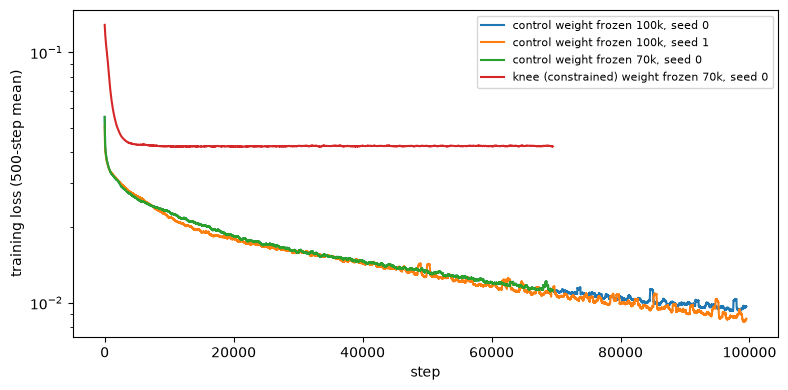

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, n in enumerate(nets):
    loss = np.asarray(n["hist"]["loss"])
    ax.plot(np.convolve(loss, np.ones(500) / 500, mode="valid"), color=f"C{i}", label=n["label"])
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("training loss (500-step mean)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Task variance: frozen vs trainable control

Same clustering as `cog20_zoom_analysis.ipynb` (Yang et al. 2019): active neurons (total task variance > 1% of
max), each normalised to its max over the 20 tasks, k-means for k = 2-20, k chosen by silhouette. Null: each
neuron's task-variance vector shuffled across tasks (5 shuffles) and re-clustered at the chosen k.

Frozen control: seed 0 (W_in, W_out frozen, 70k). Trainable control: all 12 seeds of
`dale_all_4pt_12seed_50k` (silhouette curve = mean ± std), its median-accuracy seed for the map.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 21)

def tv_clusters(tv, k_range=K_RANGE, seed=0):
    tv = np.asarray(tv)
    total = tv.sum(axis=0)
    active = total > 1e-2 * total.max()
    norm = tv[:, active] / tv[:, active].max(axis=0, keepdims=True)
    X = norm.T
    scores, labs = {}, {}
    for k in k_range:
        if k >= len(X):
            break
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
        scores[k] = silhouette_score(X, labs[k])
    k = max(scores, key=scores.get)
    lab = labs[k]
    labels = np.full(tv.shape[1], -1)
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(k)}
    order = sorted(range(k), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    remap = {c: i for i, c in enumerate(order)}
    labels[active] = [remap[c] for c in lab]
    return dict(active=active, X=X, norm_full=tv / np.maximum(tv.max(axis=0, keepdims=True), 1e-30),
                labels=labels, k=k, silhouette=scores[k], scores=scores)

def null_silhouette(X, k, n=5, seed=0):
    rng = np.random.default_rng(seed)
    return float(np.mean([silhouette_score(Xs := np.array([rng.permutation(r) for r in X]),
                                           KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Xs))
                          for _ in range(n)]))

def tv_row(name, ck, cl):
    n_sel = (cl["X"] > 0.5).sum(axis=1)
    mr = np.asarray(ck["mean_rate"])
    return {"network": name, "n_active": int(cl["active"].sum()), "k": cl["k"], "silhouette": cl["silhouette"],
            "null_silhouette": null_silhouette(cl["X"], cl["k"]), "tasks_per_neuron": float(n_sel.mean()),
            "single_task_frac": float((n_sel == 1).mean()), "active_per_task": float((mr > 0.05 * mr.max()).mean())}

# every frozen control network
CL_FZ, rows = {}, []
for n in nets:
    if n["row"]["point"] != "control":
        continue
    with contextlib.redirect_stdout(io.StringIO()):
        _, _, ck_fz = load_checkpoint(MOO_ZOOM_RUNS_DIR / n["run"] / n["row"]["checkpoint"])
    CL_FZ[n["label"]] = tv_clusters(ck_fz["task_variance"])
    rows.append(tv_row(n["label"], ck_fz, CL_FZ[n["label"]]))
n_fz = len(rows)

# trainable control, all seeds
CL_TR, ck_tr = {}, {}
for r in ref.itertuples():
    with contextlib.redirect_stdout(io.StringIO()):
        _, _, ck = load_checkpoint(MOO_ZOOM_RUNS_DIR / REF[0] / r.checkpoint)
    CL_TR[r.seed], ck_tr[r.seed] = tv_clusters(ck["task_variance"]), ck
    rows.append(tv_row(f"control trainable (50k, s{r.seed})", ck, CL_TR[r.seed]))
tvt = pd.DataFrame(rows).set_index("network")
tvt["silhouette_excess"] = tvt.silhouette - tvt.null_silhouette
summary = pd.concat([tvt.iloc[:n_fz], tvt.iloc[n_fz:].mean().to_frame(f"control trainable: mean of {len(ref)} seeds").T,
                     tvt.iloc[n_fz:].std().to_frame("  (std)").T])
display(summary.round(3))

,n_active,k,silhouette,null_silhouette,tasks_per_neuron,single_task_frac,active_per_task,silhouette_excess
"control weight frozen 100k, seed 0",234.000,3.0,0.216,0.048,7.526,0.009,0.763,0.169
"control weight frozen 100k, seed 1",211.000,2.0,0.203,0.059,8.787,0.009,0.712,0.144
"control weight frozen 70k, seed 0",236.000,3.0,0.237,0.049,6.936,0.008,0.772,0.188
control trainable: mean of 12 seeds,255.667,2.0,0.220,0.079,4.977,0.073,0.809,0.141
(std),0.492,0.0,0.024,0.012,0.325,0.039,0.046,0.018


## Silhouette score vs k

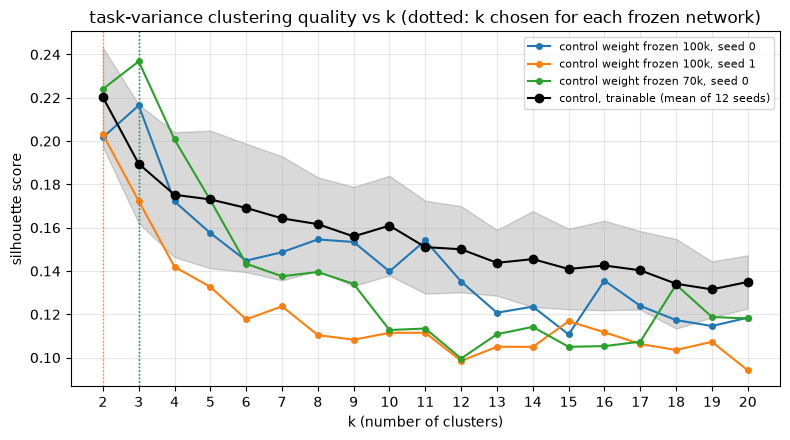

In [7]:
ks = list(K_RANGE)
tr = np.array([[CL_TR[s]["scores"].get(k, np.nan) for k in ks] for s in CL_TR])
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (lab, cl) in enumerate(CL_FZ.items()):
    ax.plot(ks, [cl["scores"].get(k, np.nan) for k in ks], "-o", ms=4, color=f"C{i}", label=lab)
    ax.axvline(cl["k"], color=f"C{i}", ls=":", lw=1)
ax.plot(ks, np.nanmean(tr, axis=0), "-o", color="k", label=f"control, trainable (mean of {len(CL_TR)} seeds)")
ax.fill_between(ks, np.nanmean(tr, 0) - np.nanstd(tr, 0), np.nanmean(tr, 0) + np.nanstd(tr, 0), color="k", alpha=0.15)
ax.set_xlabel("k (number of clusters)"); ax.set_ylabel("silhouette score"); ax.set_xticks(ks)
ax.set_title("task-variance clustering quality vs k (dotted: k chosen for each frozen network)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Normalised task-variance maps (Yang 2019, Fig. 2b layout)

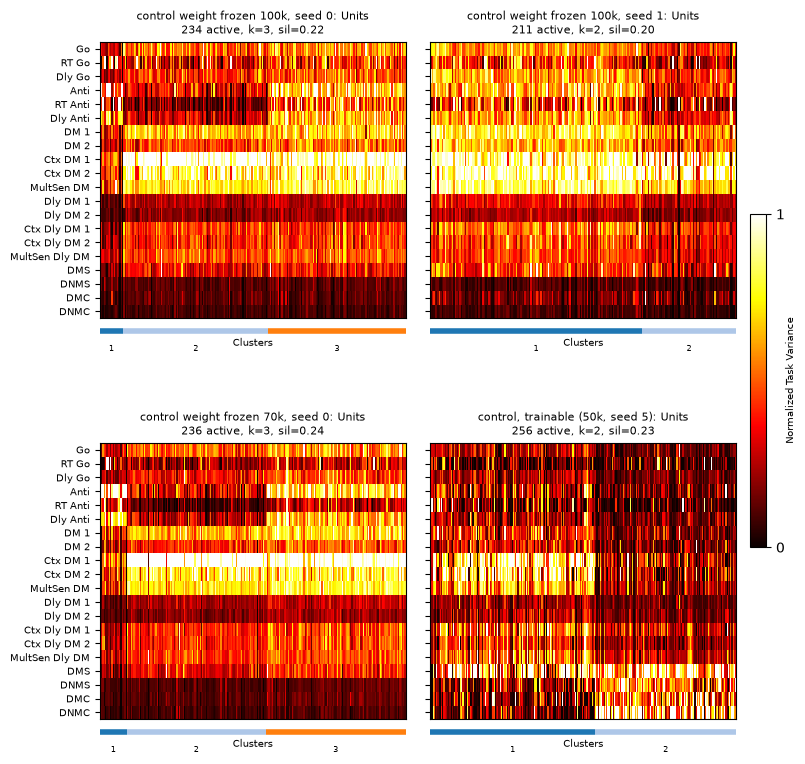

In [8]:
CLUSTER_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))
N_E = 204

def plot_variance(ax, cl, title):
    idx = np.flatnonzero(cl["active"])
    idx = idx[np.lexsort((idx >= N_E, cl["labels"][idx]))]
    im = ax.imshow(cl["norm_full"][:, idx], cmap="hot", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
    ax.set_yticks(range(len(TASKS))); ax.set_yticklabels(TNAME, fontsize=7)
    ax.set_xticks([]); ax.set_title(title, fontsize=8); ax.set_xlabel("Clusters", fontsize=7, labelpad=14)
    labs = cl["labels"][idx]
    y = len(TASKS) - 0.5 + 0.9
    for c in range(cl["k"]):
        pos = np.flatnonzero(labs == c)
        if len(pos):
            ax.plot([pos[0] - 0.5, pos[-1] + 0.5], [y, y], lw=4, solid_capstyle="butt",
                    color=CLUSTER_COLORS[c % 20], clip_on=False)
            ax.text(pos.mean(), y + 1.0, str(c + 1), ha="center", va="top", fontsize=6)
    ax.set_ylim(len(TASKS) - 0.5, -0.5)
    return im

srt = ref.sort_values("min_task_acc")
rep = int(srt.iloc[len(srt) // 2].seed)
panels = list(CL_FZ.items()) + [(f"control, trainable (50k, seed {rep})", CL_TR[rep])]
nrows = int(np.ceil(len(panels) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(2 * 4.3, 4.4 * nrows), squeeze=False)
for i, (ax, (title, cl)) in enumerate(zip(axes.flat, panels)):
    im = plot_variance(ax, cl, f"{title}: Units\n{cl['active'].sum()} active, k={cl['k']}, sil={cl['silhouette']:.2f}")
    if i % 2 == 1:
        ax.set_yticklabels([])
for ax in axes.flat[len(panels):]:
    ax.axis("off")
fig.subplots_adjust(hspace=0.45, wspace=0.08)
cb = fig.colorbar(im, ax=axes, ticks=[0, 1], fraction=0.025, pad=0.02)
cb.set_label("Normalized Task Variance", fontsize=7, labelpad=0)
plt.show()

# W_rec weights before and after training (E→E, E→I, I→E, I→I)

Same blocks and definitions as `cog20_zoom_analysis.ipynb` §2: `W[pre, post]`, magnitudes |w|, a synapse is
**present** if its E/I-normalised |w| > 1e-2. **Before** = the network's own init, rebuilt from its seed (the
inits of the different seeds have the same distribution, so they are pooled into one grey dashed line).
**After** = each trained network (solid); the trainable control is pooled over its 12 seeds. Legend: fraction
of possible synapses present.

In [9]:
BLOCKS = {"E→E": (slice(0, N_E), slice(0, N_E)), "E→I": (slice(0, N_E), slice(N_E, None)),
          "I→E": (slice(N_E, None), slice(0, N_E)), "I→I": (slice(N_E, None), slice(N_E, None))}

def block_vals(model, W):
    mag_norm = np.abs(W) / model.ei_row_scale().numpy()[:, None]
    mask = model.no_autapse.numpy() > 0
    out = {}
    for b, (pre, post) in BLOCKS.items():
        present = (mag_norm[pre, post] > 1e-2) & mask[pre, post]
        out[b] = (np.abs(W[pre, post])[present], mask[pre, post].sum())
    return out

def init_of(ck):
    with contextlib.redirect_stdout(io.StringIO()):
        m0 = make_dale_model(default_config(n_eachring=16, seed=0), **ck["model_kwargs"])
    return m0, m0.effective_w_rec().detach().numpy()

CASES = {}       # label -> {block: (values, n_possible)} pooled over the case's networks
init_pool = {}
def add(label, model, W):
    for b, (v, n) in block_vals(model, W).items():
        vs, ns = CASES.setdefault(label, {}).get(b, ([], 0))
        CASES[label][b] = (vs + [v], ns + n)

for n in nets:
    with contextlib.redirect_stdout(io.StringIO()):
        model, _, ck = load_checkpoint(MOO_ZOOM_RUNS_DIR / n["run"] / n["row"]["checkpoint"])
    add(n["label"], model, model.effective_w_rec().detach().numpy())
    m0, W0 = init_of(ck)
    init_pool[ck["model_kwargs"]["seed"]] = (m0, W0)
for r in ref.itertuples():
    with contextlib.redirect_stdout(io.StringIO()):
        model, _, ck = load_checkpoint(MOO_ZOOM_RUNS_DIR / REF[0] / r.checkpoint)
    add(f"unfrozen control (50k, {len(ref)} seeds)", model, model.effective_w_rec().detach().numpy())
for seed, (m0, W0) in init_pool.items():
    add("init (before training)", m0, W0)
CASES = {lab: {b: (np.concatenate(v), n) for b, (v, n) in d.items()} for lab, d in CASES.items()}

rows = []
for lab, d in CASES.items():
    for b, (v, n) in d.items():
        top = np.sort(v)[::-1]
        rows.append({"case": lab, "block": b, "density": len(v) / n,
                     "median |w|": np.median(v) if len(v) else np.nan,
                     "std log10|w|": np.std(np.log10(v)) if len(v) > 1 else np.nan,
                     "top10% share": top[: max(1, len(top) // 10)].sum() / top.sum() if len(v) else np.nan})
wtab = pd.DataFrame(rows).set_index(["block", "case"])
display(wtab.round(4))

,,density,median |w|,std log10|w|,top10% share
block,case,,,,
E→E,"control weight frozen 100k, seed 0",0.6393,0.0281,0.3538,0.4614
E→I,"control weight frozen 100k, seed 0",0.7123,0.0293,0.3122,0.3598
I→E,"control weight frozen 100k, seed 0",0.7082,0.1176,0.3221,0.3443
I→I,"control weight frozen 100k, seed 0",0.6912,0.1056,0.2590,0.2619
E→E,"control weight frozen 100k, seed 1",0.7252,0.0343,0.3512,0.3856
E→I,"control weight frozen 100k, seed 1",0.7993,0.0383,0.3306,0.3316
I→E,"control weight frozen 100k, seed 1",0.7916,0.1547,0.3366,0.3273
I→I,"control weight frozen 100k, seed 1",0.7881,0.1361,0.2897,0.2633
E→E,"control weight frozen 70k, seed 0",0.6596,0.0277,0.3321,0.4153


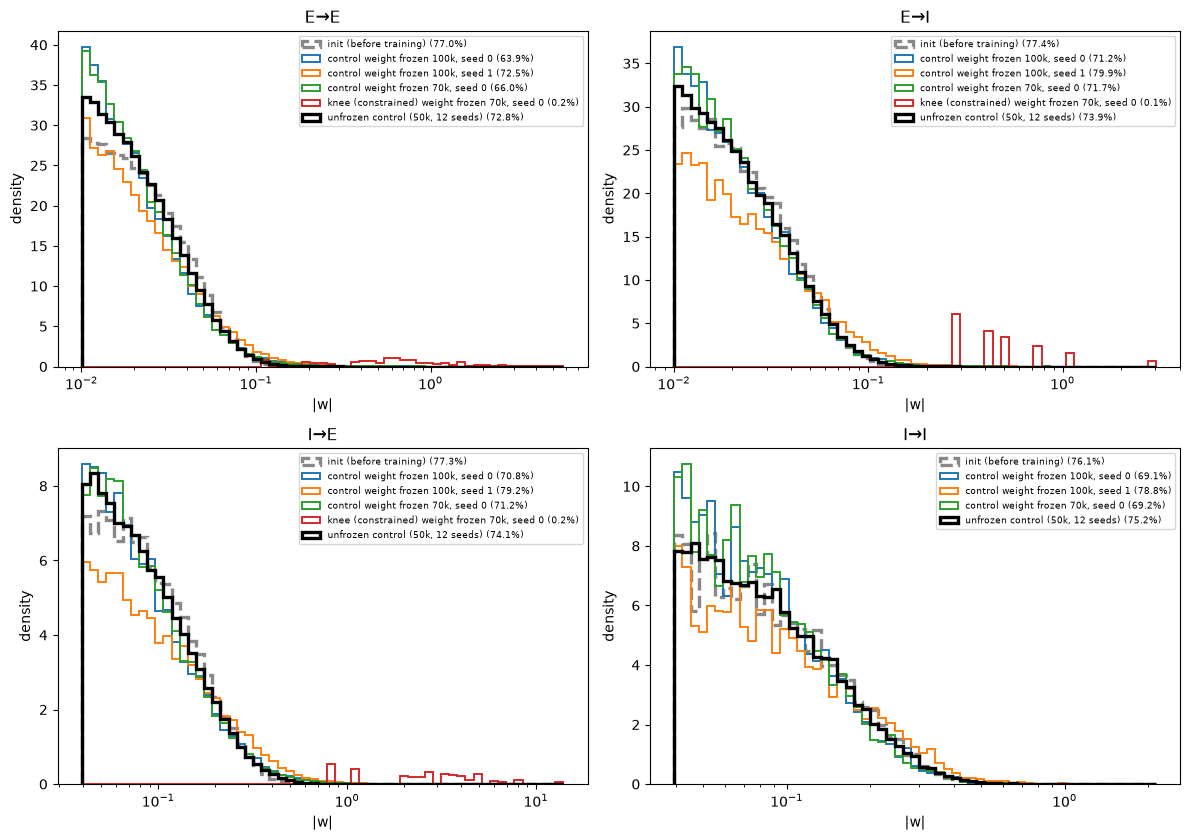

In [10]:
order = ["init (before training)"] + [n["label"] for n in nets] + [f"unfrozen control (50k, {len(ref)} seeds)"]
col = {order[0]: "#888888", order[-1]: "black", **{n["label"]: f"C{i}" for i, n in enumerate(nets)}}
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for ax, b in zip(axes.flat, BLOCKS):
    allv = np.concatenate([CASES[c][b][0] for c in order if len(CASES[c][b][0])])
    bins = np.logspace(np.log10(np.percentile(allv, 0.1)), np.log10(allv.max()), 60)
    for c in order:
        v, n = CASES[c][b]
        if len(v):
            ax.hist(v, bins=bins, density=True, histtype="step", color=col[c],
                    lw=2.4 if c in (order[0], order[-1]) else 1.4, ls="--" if c == order[0] else "-",
                    label=f"{c} ({len(v) / n:.1%})")
    ax.set_xscale("log"); ax.set_title(b); ax.set_xlabel("|w|"); ax.set_ylabel("density")
    ax.legend(fontsize=6.5)
plt.tight_layout(); plt.show()